Simulate a AT schedule from a trajectory.
- Take in params
- output Simulated AT

Simulate a complete trial. 

In [ ]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
import shutil


import matplotlib.pyplot as plt
from at_modelling.LotkaVolterraModel import LotkaVolterraModel




Lets call instantiate a lotka volterra model. We can call the paramDic to see what params it has set

In [5]:
#the model is set with default params
lv_model = LotkaVolterraModel()

print(f'Params:', lv_model.param_dic)
print(f'StateVars', lv_model.state_vars)

lv_model.set_params(rs=1)
lv_model.simulate_at(tumour_size_when_progressed=1.2)
lv_model.ode_df


Params: {'DMax': 1, 'rS': 0.027, 'rR': 0.027, 'K': 1, 'dD': 1.5, 'dS': 0.0, 'dR': 0.0, 'S0': 0.74, 'R0': 0.01, 'sigma': 0}
StateVars ['S', 'R']


,Time,DrugConcentration,S,R,TumourSize
0,0.000,1.0,0.740000,0.010000,0.750000
1,0.001,1.0,0.739998,0.010000,0.749998
2,0.002,1.0,0.739995,0.010000,0.749995
3,0.003,1.0,0.739993,0.010000,0.749993
4,0.004,1.0,0.739990,0.010000,0.749990
...,...,...,...,...,...
996,455.996,1.0,0.263583,0.636842,0.900425
997,455.997,1.0,0.263583,0.636843,0.900426
998,455.998,1.0,0.263583,0.636845,0.900428
999,455.999,1.0,0.263582,0.636847,0.900429


But it wont simulate yet. If you uncomment and run the following block, you should get an error that the model doesn't have an 'initialStateList'

In [3]:
#model_example.simulate_at()

We can set our own initial state list, or simply call the Setparams which will get the values from the param dic (R0, S0). Note that a number of arguments can be passed 

We see that We can the print the results. The default time resolution is very high. We can clean the df to longer intervals and also be sure to remove post progression obs

## part 2
We can use the model simulate an entire trial. We can the use this data to test out inferential pipeline such as a bayesian fitting routine. We can add some makeshift, but the proper way to do it would be flexible model code. 

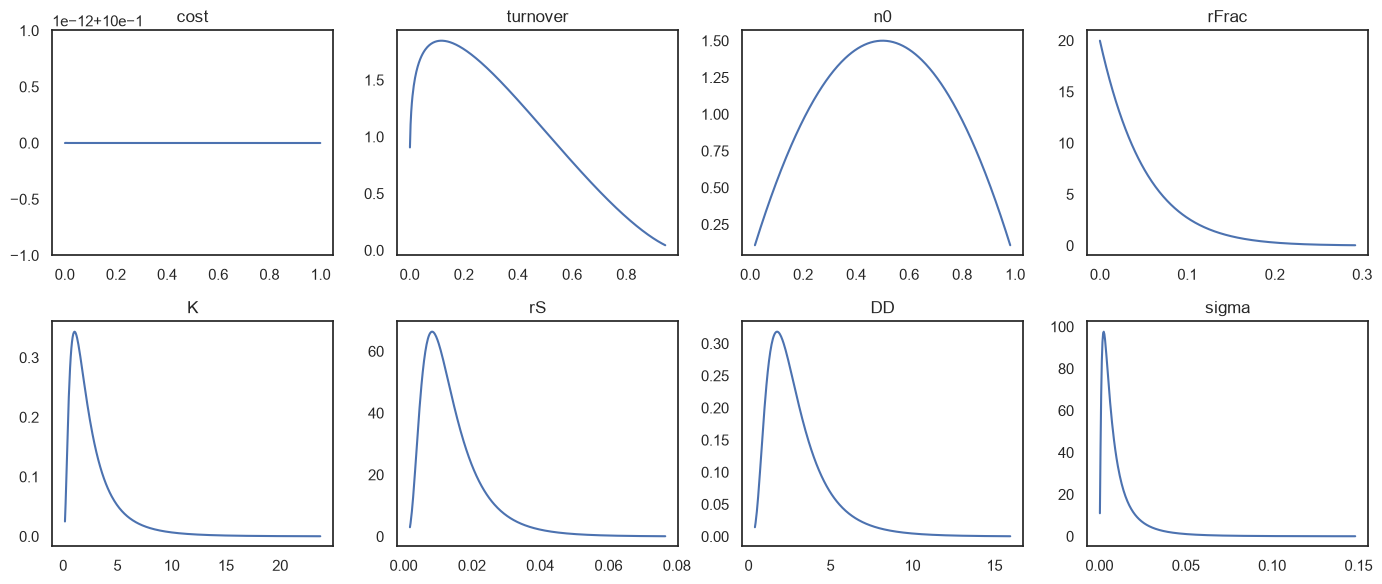

In [4]:
priorDic = {
    "cost":     stats.beta(1, 1),                       
    "turnover": stats.beta(1.2, 2.5),
    "n0":       stats.beta(2, 2),
    "rFrac":    stats.beta(1, 20),                    
    "K":        stats.lognorm(s=0.8, scale=2),
    "rS":       stats.lognorm(s=0.6, scale=0.012),
    "DD":       stats.lognorm(s=0.6, scale=2.5),
    'sigma':    stats.lognorm(s=1, scale=np.exp(-5)),
}


def draw_params(priorDic : dict):
    """Contstruct a dictionary of sampled values from prior dict"""
    return {paramName: dist.rvs() for paramName, dist in priorDic.items()}

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, dist) in zip(axes.flat, priorDic.items()):
    x = np.linspace(*dist.ppf([0.001, 0.999]), 400)
    ax.plot(x, dist.pdf(x)); ax.set_title(name)
plt.tight_layout()




In [5]:
np.random.seed(1)

def add_cycle_col(Df, treatment_col):
    '''Function to add cycle identifier'''
    Df['Cycle'] = Df[treatment_col].ne(Df[treatment_col].shift()).cumsum()
    return Df

def random_params(paramRange):
    """Selects parameters randomly from output range"""
    output = {}
    for param in paramRange():
        if isinstance(paramRange[key], list):
            assert len(paramRange[key])==2, "Lists have upper and lower bound only"
            output[key] = np.random.uniform(*paramRange[key])
        else:
            output[key] = paramRange[key]
    return output

def complete_param_dict(cost, turnover, n0, rFrac, rS, K, DD, sigma):
    """Pass unpacked dict to generate param dict in
    form required by model class.
    N.B rS is a defualt value from literatue"""
    return {"Cost": cost, "Turnover": turnover,
                "n0": n0, "R0": rFrac * n0, "S0": (n0 - rFrac*n0),
                "rS": rS, "rR": rS * (1-cost),
                "dS": rS * turnover, "dR": rS * turnover,
                'K': K, 'dD': DD, 'sigma' : sigma}

def test_progression_at(model, t_end):
    """Selects for patients that reach progression (20% growth
    from initial size) within t_end days, under rule of thumb 
    AT treatment.
    """
    output = max(model.resultsDf['Time']) + day_interval < t_end
    return int(output)


# Generate random patients
n_patients = 1000
check_progression = True
t_end = 5000  # Ensure progression occurs in this period

#steady state check
def progress_on_ct(paramDic):
    """Return true if the params would even progress on continous therapy using the derivsation of Kit Gallagher'
    s DRL paper."""
    progressCTflag = paramDic['Turnover'] < (1 - 1.2 * (paramDic['S0']+paramDic['R0'])/paramDic['K']) * (1 - paramDic['Cost'])
    return(progressCTflag)


#setup path
out_dir = Path('../synth_data')
shutil.rmtree(out_dir, ignore_errors=True) #delete if exists
out_dir.mkdir(parents=True)\

for i in range(n_patients):
    #run loop until viable param combination is found
    while True:
        priorDrawDic = draw_params(priorDic)
        priorDrawDic['K'] = 1
        paramDic = complete_param_dict(**priorDrawDic)
        if not progress_on_ct(paramDic=paramDic):
            print("Analytically doesnt progress CT")
            continue
        model = LotkaVolterraModel(method='RK45', dt=1)
        model.set_params(**{k: v for k, v in paramDic.items() if k not in ("Cost", "Turnover", "n0")})
        model.simulate_at(at_threshold=0.5, interval_length=28, t_end=t_end)
        if not np.isnan(model.ttp) or not check_progression:
            print(f"Check passed or not checking progression on AT! Saving Patient {i} out of {n_patients}")
            break
        print("Check failed")
    #break out while loop and store found param combination
    model.ode_df.to_csv(f'../synth_data/patient_{i}_ODEdf.csv')
    obsDf = pd.DataFrame(model.obs_list)
    obsDf = add_cycle_col(obsDf, 'DrugConcentration')
    obsDf.to_csv(f'../synth_data/patient_{i}_OBSdf.csv')
    
    priorDrawDic["PatientId"] = i
    if i == 0:
        df = pd.DataFrame(priorDrawDic, index=[0])
    else:
        df = pd.concat([df, pd.DataFrame(priorDrawDic, index=[i])])
df.to_csv(f"../synth_data/randSynthetic{n_patients}Patients.csv")



Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 0 out of 1000
Analytically doesnt progress CT
Analytically doesnt progress CT
Analytically doesnt progress CT
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 1 out of 1000
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 2 out of 1000
Check passed or not checking progression on AT! Saving Patient 3 out of 1000
Analytically doesnt progress CT
Analytically doesnt progress CT
Analytically doesnt progress CT
Analytically doesnt progress CT
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 4 out of 1000
Analytically doesnt progress CT
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 5 out of 1000
Analytically doesnt progress CT
Check passed or not checking progression on AT! Saving Patient 6 out of 1000
Check passed 

KeyboardInterrupt: 

Lets plot the patients we just generated.

array([[<Axes: title={'center': 'Time'}>,
        <Axes: title={'center': 'Cycle'}>]], dtype=object)

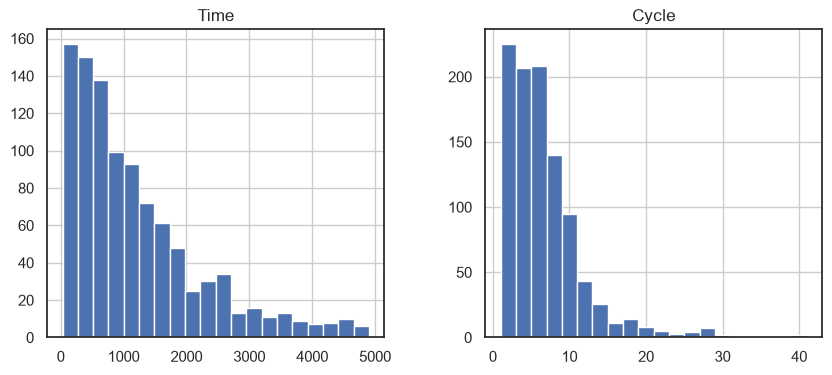

In [ ]:
import glob
import re
files = glob.glob('../synth_data/*OBSdf.csv')
pattern = r'-?\d+\.?\d*'
dfs = [pd.read_csv(file) for file in files] 
identifiers = [re.findall(pattern, file)[0] for file in files]
df = pd.concat([df.assign(PatientID = id) for id, df in zip(identifiers, dfs)]).reset_index(drop=True)

summary = df.groupby('PatientID').agg({'Time': 'max', 'Cycle': 'max' })
summary.hist(bins=20, figsize=(10, 4))


array([[<Axes: title={'center': 'Days'}>,
        <Axes: title={'center': 'Cycle'}>]], dtype=object)

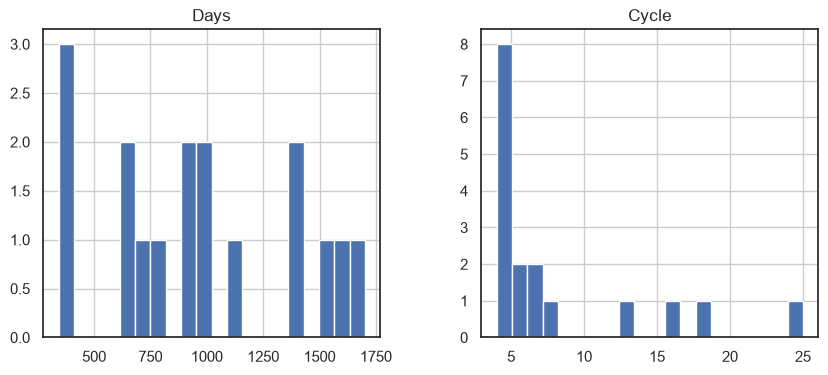

In [ ]:
import glob
import re
files = glob.glob('../data/*.csv')
pattern = r'-?\d+\.?\d*'
dfs = [pd.read_csv(file) for file in files]
dfs = [add_cycle_col(df, treatment_col='Abi') for df in dfs]
identifiers = [re.findall(pattern, file)[0] for file in files]
df = pd.concat([df.assign(PatientID = id) for id, df in zip(identifiers, dfs)]).reset_index(drop=True)

summary = df.groupby('PatientID').agg({'Days': 'max', 'Cycle': 'max' })
summary.hist(bins=20, figsize=(10, 4))


### part 3
Fit all of these using stan

In [ ]:
import cmdstanpy

def to_stan_prior(dist):
    """scipy beta(a, b) -> [a, b], scipy lognorm(s, scale) -> [log(scale), s] as in Stan's lognormal(mu, sigma)"""
    if dist.dist.name == 'beta':
        return list(dist.args)
    if dist.dist.name == 'lognorm':
        return [float(np.log(dist.kwds['scale'])), dist.kwds['s']]
    raise ValueError(f"No Stan conversion for {dist.dist.name}")

#priors in the fit are the priorDic the patients were drawn from. priorDic uses DD, the Stan model dD
stan_name = {'DD': 'dD'}
priors = {f"{stan_name.get(k, k)}_prior": to_stan_prior(d) for k, d in priorDic.items()}
fixed_vals = {'K': 1}  #K is fixed at 1 when generating the patients, so K_prior is not used

#data windows as the number of cycles kept, as synth_windows in R/synth_functions.R
synth_windows = {'first_cycle': 1, 'two_cycles': 2, 'full_history': np.inf}

synth_dir = Path('../synth_data')
fit_root = Path('../fits/synth_python')
stan_model = cmdstanpy.CmdStanModel(stan_file='../stan/model_switchable.stan')


In [ ]:
switchable_params = ["cost", "turnover", "n0", "rFrac", "rS", "K", "dD"]

def make_fixed_val_data(fixed_vals):
    """fit_<param> flags (1 = fitted) and <param>_fixed_val values, as make_fixed_val_data in R/functions.R"""
    unknown = set(fixed_vals) - set(switchable_params)
    assert not unknown, f"not switchable: {unknown}"
    flags = {f"fit_{p}": int(p not in fixed_vals) for p in switchable_params}
    vals = {f"{p}_fixed_val": fixed_vals.get(p, 0) for p in switchable_params}
    return {**flags, **vals}

def load_synth_patient(patient_id):
    """Load one patient's observations, as load_synth_patient in R/synth_functions.R.
    DrugConcentration in the csv is the dose leading up to a visit, dose_from is the dose from the visit on"""
    df = pd.read_csv(synth_dir / f'patient_{patient_id}_OBSdf.csv', index_col=0).sort_values('Time').reset_index(drop=True)
    dose_before = df['DrugConcentration']
    df['dose_from'] = dose_before.shift(-1).fillna(dose_before.iloc[-1]).astype(int)
    #a cycle starts at each visit where treatment restarts after a holiday. The baseline visit is recorded with dose 0
    #but has no interval before it, so the first treated visit is not a restart
    restart = (dose_before == 1) & (dose_before.shift() == 0)
    restart.iloc[:2] = False
    df['CycleId'] = 1 + restart.cumsum()
    df['segment'] = df['dose_from'].ne(df['dose_from'].shift()).cumsum()
    return df

def make_stan_data(patient_id, n_cycles=np.inf, prior_only=0):
    """Stan data for model_switchable.stan, as make_switchable_stan_data in R/fit_synth_switchable.R.
    n0 is fitted and the model is compared with the raw observations (fit_psa0 = 0)"""
    patient_df = load_synth_patient(patient_id)
    patient_df = patient_df[patient_df.CycleId <= n_cycles]

    #constant dose segments between visits. A segment that would start at the last visit has no follow up, so is dropped
    seg = patient_df.groupby('segment').agg(start=('Time', 'first'), treatment=('dose_from', 'first'))
    seg['end'] = seg['start'].shift(-1, fill_value=patient_df.Time.max())
    seg = seg[seg.end > seg.start]

    #every visit has an observation, so the output times are the visit times
    output_times = np.unique(np.r_[patient_df.Time, seg.end])
    to_idx = np.searchsorted(output_times, seg.end) + 1  #Stan is 1-indexed
    from_idx = np.r_[1, to_idx[:-1] + 1]

    return {
        'n_segments': len(seg),
        'starting_segment_times': seg.start.astype(int).tolist(),
        'end_segment_times': seg.end.astype(int).tolist(),
        'treatment_indicator': seg.treatment.astype(int).tolist(),
        'n_out': len(output_times),
        'output_times': output_times.astype(float).tolist(),
        'segment_from_idx': from_idx.tolist(),
        'segment_to_idx': to_idx.tolist(),
        'n_obs': len(patient_df),
        'obs_idx': (np.searchsorted(output_times, patient_df.Time) + 1).tolist(),
        'PSA_norm': patient_df.Observation.tolist(),
        **make_fixed_val_data(fixed_vals),
        'fit_psa0': 0,
        'psa0_prior': [0, 1],  #not used with fit_psa0 = 0
        'prior_only': prior_only,
        **priors,
        'run_diagnostics': 1,
    }

make_stan_data(0, n_cycles=1)


In [ ]:
def draw_prior_init(rng):
    """One prior draw per chain. Stan's default inits can put rS high enough that the ODE gets stiff (see R/fit_synth_switchable.R)"""
    draw = {p: priorDic[p].rvs(random_state=rng) for p in ['cost', 'turnover', 'n0', 'rFrac', 'rS', 'DD']}
    draw['rFrac'] = max(draw['rFrac'], 1e-8)  #small rFrac draws can underflow to 0, outside the support
    return {**{f"{stan_name.get(p, p)}_free": [v] for p, v in draw.items()},
            'sigma': priorDic['sigma'].rvs(random_state=rng)}

def fit_patient(patient_id, window, chains=4, seed=1, adapt_delta=0.95, timeout=None):
    """Fit one patient on one window. CSVs go in fits/synth_python/<window>/patient<id>.
    adapt_delta .95 as in R/fit_synth_switchable.R, where .8 gave divergences"""
    rng = np.random.default_rng(patient_id)  #inits are seeded per patient
    return stan_model.sample(data=make_stan_data(patient_id, synth_windows[window]),
                             inits=[draw_prior_init(rng) for _ in range(chains)],
                             chains=chains, parallel_chains=chains, seed=seed, adapt_delta=adapt_delta,
                             output_dir=fit_root / window / f'patient{patient_id:03d}',
                             show_progress=False, timeout=timeout)


In [ ]:
#fit one patient on the first cycle and compare with the true parameters
truth = pd.read_csv(next(synth_dir.glob('randSynthetic*Patients.csv')), index_col=0).rename(columns={'DD': 'dD'}).set_index('PatientId')
fit_params = ['cost', 'turnover', 'n0', 'rFrac', 'rS', 'dD', 'sigma']

patient_id = 0
fit = fit_patient(patient_id, 'first_cycle')
fit_summary = fit.summary().loc[fit_params, ['Mean', '5%', '95%', 'R_hat', 'ESS_bulk']]
fit_summary['truth'] = truth.loc[patient_id, fit_params]
print(fit.diagnose())
fit_summary


In [ ]:
#fit every patient on every window. Patients with a saved fit are skipped, so this can be stopped and rerun
for patient_id in sorted(truth.index):
    for window in synth_windows:
        out_dir = fit_root / window / f'patient{patient_id:03d}'
        if out_dir.exists():
            continue
        try:
            fit = fit_patient(patient_id, window, timeout=600)
            print(f"patient {patient_id} {window}: done, {fit.divergences.sum()} divergences")
        except (RuntimeError, TimeoutError) as e:
            print(f"patient {patient_id} {window}: failed ({type(e).__name__})")
